# Assignment 5: Predicting Class Label

**Sally Choi**  
**DATASCI 530**


## Project overview

For this project, I used the UCI Iris dataset to examine whether a flower's species can be predicted from its sepal and petal measurements. The dataset contains 150 flowers from three species: setosa, versicolor, and virginica. Each flower has four measurements recorded in centimeters, which serve as the predictors for the classification models.

I started by checking the data for missing values and comparing the measurements across species. I then fitted an SVM, random forest, neural network, and ridge classifier, using the same five cross-validation folds to compare their accuracy and macro F1 scores. After testing the default SVM, I used a grid search to see whether different settings would improve its predictions. Finally, I looked at the errors made by the two leading models and tested whether petal or sepal measurements alone could perform nearly as well as all four predictors.

### Key findings

The dataset has **50 flowers per species** and no missing measurements or labels. The **tuned SVM and random forest tied at 96.67% accuracy and 0.9666 macro F1**, with each correctly classifying 145 of the 150 flowers. The default SVM was close behind at **96.00% accuracy**, so tuning added only one correct prediction. The neural network and ridge classifier achieved **90.67%** and **84.67% accuracy**, respectively.

Both leading models correctly classified every setosa flower, while all their errors occurred between versicolor and virginica. The petal-only SVM reached **96.00% accuracy**, compared with **76.67%** using sepals alone, suggesting that petal measurements provided most of the useful predictive information. Based on these results, I recommend either the tuned SVM or random forest, although their small advantage over the default SVM should be interpreted cautiously given the sample size.


## 1. Dataset description

### Load the data

I loaded the [UCI Iris dataset](https://archive.ics.uci.edu/dataset/53/iris), which includes sepal length, sepal width, petal length, and petal width for each flower. I stored these four measurements in `X` and the species labels in `y` so that the information used to make predictions stays separate from the answer being predicted. Since the class label is the outcome, it is not counted as a predictor.


In [4]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
from IPython.display import display

# Load Iris data
iris = fetch_ucirepo(id=53)
X = iris.data.features
y = iris.data.targets

# Combine measurements and labels
iris_data = pd.concat([X, y], axis=1)


### Dataset size and initial checks

Before fitting any models, I checked how many observations and predictors were available and whether any measurements or species labels were missing. I also checked that the predictor and label row indices matched, so each flower's measurements would be paired with its species label. Table 1 summarizes these checks and helps determine whether any values need to be filled in before analysis.


In [5]:
# Check matching row indices
assert X.index.equals(y.index), "Predictors and class labels must have matching rows."

# Count rows features and missing values
dataset_summary = pd.DataFrame({
    "Measure": ["Observations (rows)", "Predictor features", "Missing predictor values", "Missing class labels"],
    "Count": [X.shape[0], X.shape[1], X.isna().sum().sum(), y.isna().sum().sum()]
})

display(dataset_summary.style.hide(axis="index").set_caption("Table 1. Dataset size and missing-value checks"))


Measure,Count
Observations (rows),150
Predictor features,4
Missing predictor values,0
Missing class labels,0


### Class distribution

I counted the flowers in each species and divided each count by the total sample size to calculate the percentages in Table 2. This shows whether the classes are balanced or whether one species makes up a larger share of the data, which could affect how I interpret the classification results.


In [6]:
# Count flowers per species
class_counts = y["class"].value_counts().sort_index()

# Calculate class proportions
class_summary = pd.DataFrame({
    "Class": class_counts.index.str.replace("Iris-", "", regex=False).str.capitalize(),
    "Flowers": class_counts.to_numpy(),
    "Proportion": (class_counts / len(y)).to_numpy()
})

display(class_summary.style.format({"Proportion": "{:.1%}"}).hide(axis="index")
        .set_caption("Table 2. Number and proportion of flowers in each class"))


Class,Flowers,Proportion
Setosa,50,33.3%
Versicolor,50,33.3%
Virginica,50,33.3%


The dataset contains **150 rows and 4 predictors**, with **50 flowers from each species**. Each class therefore makes up **33.3% of the sample**, so no species is more common than the others. The measurements and labels have matching row indices, and neither contains missing values. I kept all 150 observations and did not need to fill in any missing measurements.


### Predictor types, ranges, and variation

I summarized the mean, standard deviation, median, and range of each predictor to get a better sense of the measurements before modeling. The standard deviation shows how spread out the values are, while the minimum and maximum help identify measurements that might need a closer look. I also checked for zero or negative values because flower lengths and widths should be positive.


In [7]:
# Summarize predictor measurements
predictor_summary = X.agg(["mean", "std", "median", "min", "max"]).T
predictor_summary.columns = ["Mean", "Std. deviation", "Median", "Minimum", "Maximum"]
predictor_summary.insert(0, "Data type", X.dtypes.astype(str))
predictor_summary.index = predictor_summary.index.str.title()
predictor_summary.index.name = "Predictor (cm)"

display(predictor_summary.style.format(precision=2)
        .set_caption("Table 3. Predictor types and descriptive statistics"))

# Check zero or negative measurements
print(f"Zero or negative measurements: {(X <= 0).sum().sum()}")


,Data type,Mean,Std. deviation,Median,Minimum,Maximum
Predictor (cm),,,,,,
Sepal Length,float64,5.84,0.83,5.80,4.30,7.90
Sepal Width,float64,3.05,0.43,3.00,2.00,4.40
Petal Length,float64,3.76,1.76,4.35,1.00,6.90
Petal Width,float64,1.20,0.76,1.30,0.10,2.50


Zero or negative measurements: 0


All four predictors are numeric, and there are no zero or negative measurements. Sepal length ranges from **4.30 to 7.90 cm**, while petal length ranges from **1.00 to 6.90 cm**. Petal length has the largest standard deviation at **1.76 cm**, meaning its values are more spread out than the other measurements. These checks did not reveal any nonpositive values that would need to be addressed before modeling.


### Average predictor measurements by species

The overall averages combine all three species, so I also calculated the mean of each measurement separately for setosa, versicolor, and virginica. Comparing these averages helps show which characteristics might be useful for telling the species apart. Table 4 reports the results in centimeters, rounded to two decimal places.


In [9]:
# Calculate means per species
class_means = iris_data.groupby("class")[X.columns].mean()

# Format species and column names
class_means.index = class_means.index.str.replace("Iris-", "", regex=False).str.capitalize()
class_means.index.name = "Species"
class_means.columns = class_means.columns.str.title() + " (cm)"

display(class_means.style.format("{:.2f}")
        .set_caption("Table 4. Mean sepal and petal measurements by species"))

,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm)
Species,,,,
Setosa,5.01,3.42,1.46,0.24
Versicolor,5.94,2.77,4.26,1.33
Virginica,6.59,2.97,5.55,2.03


Setosa has much smaller petals on average than the other two species, with a mean length of **1.46 cm** and width of **0.24 cm**. Versicolor's petals average **4.26 cm** long and **1.33 cm** wide, while virginica's average **5.55 cm** long and **2.03 cm** wide. Virginica also has the longest sepals on average (**6.59 cm**), whereas setosa has the widest (**3.42 cm**).

The differences in petal measurements suggest that they could be useful for predicting species. However, averages alone do not show how much individual flowers overlap, so I later compared model performance using different sets of measurements.


## 2. Comparing machine learning methods


In [2]:
# Importing libraries

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# For neural network
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense

# Model selection and preprocessing tools
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Classification methods
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import RidgeClassifier

# Evaluation metrics and confusion matrices
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)

Libraries imported successfully. TensorFlow version: 2.16.2


### Preparing the data for modeling

I used stratified five-fold cross-validation so that the comparison would not depend on just one training and evaluation split. In each round, the model learns from **120 flowers** and predicts the species of the remaining **30 flowers**. Stratification keeps 10 flowers from each species in every evaluation fold, and all four methods use the same splits. Each flower is evaluated once, with the random seed fixed so the splits can be reproduced.

I compared the methods using accuracy and macro F1. Accuracy is the proportion of flowers classified correctly, while macro F1 balances precision and recall for each species and then gives all three species equal weight. Precision considers whether predictions for a species are correct, and recall considers how many flowers of that species were identified. The scikit-learn models start with default tuning parameters, while the neural network uses fixed lecture settings. I then tune only the SVM to see whether changing its settings improves performance.


In [12]:
# Extract species labels
y_class = y["class"]

# Create five balanced folds
cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 104)

# Save splits for all models
folds = list(cv.split(X, y_class))

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "f1": "f1_macro"}

# Check training and evaluation sizes
for fold, (train_index, test_index) in enumerate(folds, start=1):
    print(
        f"Fold {fold}: "
        f"{len(train_index)} training, "
        f"{len(test_index)} evaluation")

Fold 1: 120 training, 30 evaluation
Fold 2: 120 training, 30 evaluation
Fold 3: 120 training, 30 evaluation
Fold 4: 120 training, 30 evaluation
Fold 5: 120 training, 30 evaluation


### **Support vector machine**

I first fitted the SVM using its default settings to establish a starting point before tuning. Its radial basis function (RBF) kernel allows curved boundaries between classes, which can help when the species cannot be separated by a straight boundary. Since the SVM is sensitive to predictor scales, I used a pipeline that standardizes the measurements before fitting the classifier. Within each fold, the scaler learns its means and standard deviations from the training flowers and applies those same values to the evaluation flowers.


In [13]:
# Scale inputs before SVM
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
    ])

# Evaluate SVM across folds
svm_results = cross_validate(
    svm_model,
    X,
    y_class,
    cv = folds,
    scoring = scoring,
    return_train_score = False)

### **Tuning the support vector machine**

I tested whether changing the SVM's settings would improve its predictions. The grid search tries 12 combinations of `C`, which controls how strongly the model penalizes training errors, and `gamma`, which controls how locally observations influence the classification boundary. I kept the other settings at their defaults so that the search focuses on these two parameters.

I used nested cross-validation to choose the settings without using the evaluation flowers. Within each group of 120 training flowers, an inner five-fold search selects the combination with the highest mean macro F1. The selected model is then trained on all 120 flowers and evaluated on the remaining 30. This keeps the flowers used to assess performance separate from those used to choose the settings.

Because the training flowers change in each round, the selected parameters can change too. The tuned SVM row therefore averages the evaluation scores from the tuning process rather than testing one fixed combination in every round. Scaling stays inside the pipeline so that it is learned only from the training observations at each stage.


In [25]:
# Try twelve parameter combinations
param_grid = {
    "svm__C": [0.1, 1, 10],
    "svm__gamma": ["scale", 0.01, 0.1, 1]}

# Create inner folds for tuning
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0)

svm_search = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=inner_cv,
    refit=True)

In [26]:
# Evaluate tuned SVM across outer folds
svm_tuned_results = cross_validate(
    svm_search,
    X,
    y_class,
    cv=folds,
    scoring=scoring,
    return_train_score=False,
    return_estimator=True)

In [27]:
# Show selected parameters per fold
selected_parameters = []

for fold_number, search in enumerate(
    svm_tuned_results["estimator"],
    start=1):
    selected_parameters.append({
        "Outer fold": fold_number,
        "Selected C": search.best_params_["svm__C"],
        "Selected gamma": str(search.best_params_["svm__gamma"])
        })

selected_parameters = pd.DataFrame(selected_parameters)

display(
    selected_parameters.style
    .hide(axis="index")
    .format({"Selected C": "{:.1f}"})
    .set_caption("SVM parameters selected within each training fold"))

Outer fold,Selected C,Selected gamma
1,1.0,0.1
2,10.0,scale
3,1.0,scale
4,10.0,0.01
5,1.0,scale


### **Random forest**

I fitted a random forest using its default tuning parameters and a fixed random seed. This method combines many decision trees, with each tree learning from a bootstrap sample, or a sample drawn with replacement, of the training flowers. The trees also consider random subsets of predictors when choosing splits, so the final prediction does not depend on a single tree. I used the original measurements because tree-based methods do not require scaling, and evaluated the forest using the same five folds as the other methods.


In [14]:
rf_model = RandomForestClassifier(random_state=0)

rf_results = cross_validate(
    rf_model,
    X,
    y_class,
    cv = folds,
    scoring = scoring,
    return_train_score = False)

### **Neural network**

For the neural network, I followed Lecture 16 by using a hidden layer with 16 units, the Adam optimizer with a learning rate of 0.001, and 100 training epochs. Each epoch is one pass through the training observations, during which the network adjusts its weights to reduce prediction errors. Since Iris has three species, I used three softmax outputs to give a probability for each species and sparse categorical cross-entropy to train the model using integer class labels. Keras requires an architecture to be specified, so these are fixed lecture settings rather than a default network.

For each fold, I standardized the measurements using only the training flowers and built a fresh network. This prevents the model from carrying over weights learned in a previous round. After training, I selected the species with the highest predicted probability and calculated accuracy and macro F1 on the evaluation flowers, just as I did for the other methods.


In [15]:
# Convert measurements to numeric arrays
X_nn = X.to_numpy().astype(np.float32)

# Encode species as integers
label_encoder = LabelEncoder()
y_nn = label_encoder.fit_transform(y_class)

In [16]:
# Store fold scores
nn_scores = []

for train_index, test_index in folds:
    # Select training and evaluation rows
    X_train = X_nn[train_index]
    X_test = X_nn[test_index]
    y_train = y_nn[train_index]
    y_test = y_nn[test_index]

    # Fit scaler on training data
    scaler = StandardScaler().fit(X_train)
    X_train_scale = scaler.transform(X_train)
    X_test_scale = scaler.transform(X_test)

    # Build fresh network per fold
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(0)

    basic_model = keras.models.Sequential()
    basic_model.add(keras.Input(shape=(X.shape[1],)))
    basic_model.add(Dense(units=16, activation="relu"))
    basic_model.add(Dense(units=3, activation="softmax"))

    # Set optimizer and learning rate
    adam = keras.optimizers.Adam(learning_rate=0.001)

    basic_model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=adam,
        metrics=["accuracy"])

    basic_model.fit(
        X_train_scale,
        y_train,
        epochs=100,
        verbose=0)

    # Select highest probability class
    predicted_prob = basic_model.predict(
        X_test_scale,
        verbose=0)
    
    predictions = np.argmax(predicted_prob, axis=1)

    nn_scores.append({
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_f1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0)
            })

nn_results = pd.DataFrame(nn_scores)

### **Ridge classifier**

I used ridge classification as the additional method because it provides a simpler linear comparison with the SVM, random forest, and neural network. It calculates class scores from weighted combinations of the measurements and adds a penalty that discourages very large coefficients, which can help limit overfitting. I kept the default tuning parameters and used a pipeline to standardize the predictors before fitting. This puts the measurements on a comparable scale so that their original units do not unevenly affect the penalty.


In [17]:
# Scale inputs before ridge
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", RidgeClassifier())
    ])

ridge_results = cross_validate(
    ridge_model,
    X,
    y_class,
    cv = folds,
    scoring = scoring,
    return_train_score = False)

## Cross-validation results

Table 5 compares the four methods, including both the default and tuned SVM, using their average scores across the same five evaluation folds. Higher accuracy and macro F1 indicate better performance, while the macro F1 standard deviation shows how much the scores varied between folds. This standard deviation is not a confidence interval. Since each fold contains only 30 evaluation flowers, a small change in the number of mistakes can affect the scores, so I interpret narrow differences cautiously.


In [34]:
# Collect evaluation results
model_results = {
    "SVM (default)": svm_results,
    "SVM (tuned)": svm_tuned_results,
    "Random forest": rf_results,
    "Neural network": nn_results,
    "Ridge classifier": ridge_results}

rows = []

for method, results in model_results.items():
    rows.append({
        "Method": method,
        "Mean accuracy": np.mean(results["test_accuracy"]),
        "Mean macro F1": np.mean(results["test_f1"]),
        "Macro F1 SD": np.std(results["test_f1"], ddof=1)
        })

comparison = pd.DataFrame(rows)
comparison = comparison.sort_values(
    "Mean macro F1",
    ascending=False)

display(
    comparison.style
    .hide(axis = "index")
    .format(precision = 4)
    .set_caption("Table 5. Five-fold cross-validation results"))

Method,Mean accuracy,Mean macro F1,Macro F1 SD
SVM (tuned),0.9667,0.9666,0.0236
Random forest,0.9667,0.9666,0.0236
SVM (default),0.9600,0.9600,0.0279
Neural network,0.9067,0.9052,0.0677
Ridge classifier,0.8467,0.8441,0.0326


### Interpretation of model performance

The tuned SVM and random forest performed best, both reaching **96.67% accuracy** and **0.9666 macro F1**. Each correctly classified 145 of the 150 flowers across the five evaluation folds. The default SVM was close behind at **96.00% accuracy**, so the parameter search improved the total by only one correct prediction. This is a small gain and does not provide strong evidence that tuning would consistently improve predictions on another sample.

The neural network achieved **90.67% accuracy** and **0.9052 macro F1**, with more variation in F1 across folds than the other methods. Its performance therefore appeared more sensitive to the training split under the settings used here. Ridge had the lowest scores at **84.67% accuracy** and **0.8441 macro F1**, suggesting that its regularized linear rule was less effective for this dataset.

I recommend either the tuned SVM or random forest because neither had an advantage in the reported scores. The default SVM is also a reasonable option because it performed nearly as well without a parameter search. These conclusions apply to the configurations tested here rather than showing that one method is always better.


## 3. Additional analysis

### Where do the best-performing models make mistakes?

The tuned SVM and random forest had identical summary scores, so I compared their confusion matrices to see whether they struggled with the same species. Each flower is predicted only when it is in an evaluation fold, and the SVM search stays within the training fold. In the matrices, the diagonal cells count correct predictions, while the other cells show which species were confused. I also counted how often the two models assigned different labels to the same flower, since matching overall scores do not necessarily mean matching predictions.


In [41]:
from sklearn.model_selection import cross_val_predict

# Predict held out flowers
svm_cv_predictions = cross_val_predict(
    svm_search,
    X,
    y_class,
    cv=folds)

rf_cv_predictions = cross_val_predict(
    rf_model,
    X,
    y_class,
    cv=folds)

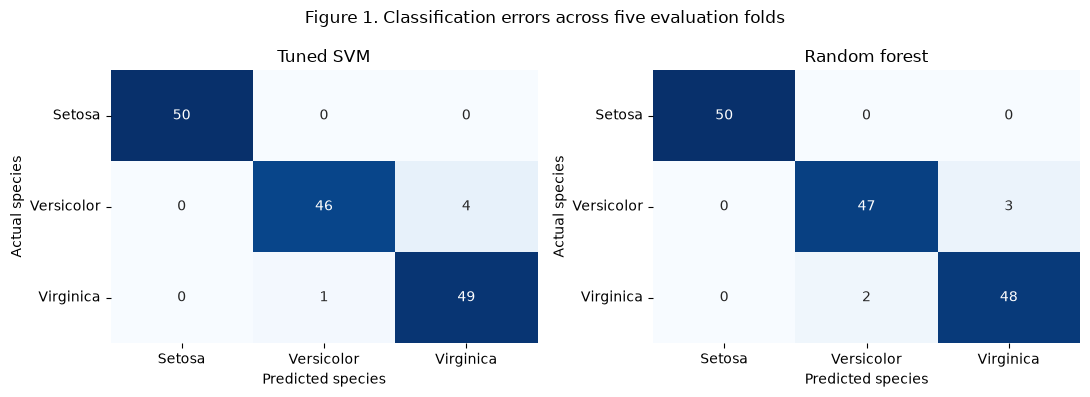

In [42]:
# Match species order across plots
species = sorted(y_class.unique())
species_names = [
    name.replace("Iris-", "").capitalize()
    for name in species
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, predictions, title in zip(
    axes,
    [svm_cv_predictions, rf_cv_predictions],
    ["Tuned SVM", "Random forest"]):
    cm = confusion_matrix(
        y_class,
        predictions,
        labels=species)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        vmin=0,
        vmax=50,
        cbar=False,
        xticklabels=species_names,
        yticklabels=species_names,
        ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("Actual species")
    ax.tick_params(axis="y", labelrotation=0)

fig.suptitle("Figure 1. Classification errors across five evaluation folds")
plt.tight_layout()
plt.show()

In [43]:
# Count disagreements between models
different_predictions = (
    svm_cv_predictions != rf_cv_predictions).sum()

print(
    f"The models give different predictions for "
    f"{different_predictions} of the 150 flowers.")

The models give different predictions for 4 of the 150 flowers.


### How much information do petal and sepal measurements provide?

The earlier class averages suggested that petal measurements might help distinguish species, so I tested whether using only those measurements would preserve most of the predictive performance. I compared the tuned SVM using sepals only, petals only, and all four measurements, keeping the same outer folds, parameter grid, and evaluation metrics. The search is repeated within each training fold for each predictor set, allowing the settings to be selected without using the evaluation flowers. This comparison shows whether adding both sepal measurements provides much improvement over measuring the petals alone.


In [44]:
# Define smaller predictor sets
feature_sets = {
    "Sepal measurements only": ["sepal length", "sepal width"],
    "Petal measurements only": ["petal length", "petal width"]}

# Reuse full predictor results
feature_results = {
    "All four measurements": svm_tuned_results}

# Evaluate smaller predictor sets
for name, columns in feature_sets.items():
    feature_results[name] = cross_validate(
        svm_search,
        X[columns],
        y_class,
        cv=folds,
        scoring=scoring,
        return_train_score=False)

In [45]:
rows = []

for name, results in feature_results.items():
    rows.append({
        "Predictors": name,
        "Number of features": (
            4 if name == "All four measurements" else 2
        ),
        "Mean accuracy": np.mean(results["test_accuracy"]),
        "Mean macro F1": np.mean(results["test_f1"]),
        "Macro F1 SD": np.std(results["test_f1"], ddof=1)
        })

feature_comparison = pd.DataFrame(rows)

display(
    feature_comparison.style
    .hide(axis="index")
    .format({
        "Number of features": "{:.0f}",
        "Mean accuracy": "{:.4f}",
        "Mean macro F1": "{:.4f}",
        "Macro F1 SD": "{:.4f}"
        })
    .set_caption(
        "Table 6. Tuned SVM performance using different predictor sets"))

Predictors,Number of features,Mean accuracy,Mean macro F1,Macro F1 SD
All four measurements,4,0.9667,0.9666,0.0236
Sepal measurements only,2,0.7667,0.7641,0.0883
Petal measurements only,2,0.9600,0.9600,0.0279


Table 6 summarizes the average accuracy, macro F1, and variation in F1 for each predictor set. I reused the all-feature results from Table 5 and compared them with the two smaller models, so the results reflect the same outer evaluation splits and tuning procedure.


## 4. Insights from the additional analyses

### Similar scores hide different errors

Figure 1 shows that both models correctly classified all **50 setosa flowers**, while all five mistakes from each model occurred between versicolor and virginica. The tuned SVM labeled four versicolor flowers as virginica and one virginica flower as versicolor. The random forest made three mistakes in the first direction and two in the second, giving it one more correct versicolor prediction but one fewer correct virginica prediction.

This helps explain why the tied scores in Table 5 do not tell the whole story. Both models found setosa easier to identify, but their errors differed slightly for the other two species. Neither performed better for every species, so the confusion matrices do not give a clear overall reason to choose one over the other.

### Petal measurements provide most of the predictive information

The petal-only SVM achieved **96.00% accuracy** and **0.9600 macro F1**, nearly matching the all-feature model's **96.67% accuracy** and **0.9666 macro F1**. Adding the sepal measurements therefore improved the total by only one correct prediction across the 150 flowers. In contrast, the sepal-only model achieved **76.67% accuracy** and **0.7641 macro F1**, so sepal measurements were much less useful on their own.

The sepal-only model also had a higher F1 standard deviation (**0.0883**) than the petal-only model (**0.0279**), meaning its performance changed more across folds. Together, these results suggest that petal length and width provided most of the information needed for prediction in this comparison. Measuring all four characteristics gave the highest scores, but using just two petal measurements offered nearly the same performance. The difference is small, so I would not assume that the two predictor sets would perform equally well on other samples.
